# **BN5211 Medical Robotic Intelligence Assignment 2**

In this project, you will embark on a deep learning journey of Medical Robotics by completing the following tasks:

*   Task 1. Building Neural Network for surgical instrument classification (40%)
*   Task 2. Surgical Action recognition (25%)
*   Task 3. Contrastive learning - Momentum Contrast for Unsupervised Visual Representation Learning (35%)


**Before doing the project, please read the instructions carefully:**

## Submission Requirements

Upload the following **two files** to **Canvas → Assignments → Assignment 2** by **6 October 2026, 23:59 SGT**.

### 1. Completed Jupyter Notebook (`.ipynb`)

* Execute all cells before submission.
* Ensure that all required outputs, figures, and results are saved and visible.
* Name the file: `<MatriculationNumber>_BN5211_Assignment2.ipynb`
  Example: `A0123456X_BN5211_Assignment2.ipynb`

### 2. One Merged PDF

Combine the following into a single PDF:

* **Notebook PDF:** Export your completed notebook using **File → Print → Save as PDF** in Google Colab.
* **Analysis Report:** Include all written analysis requested in Tasks 1-3. You may prepare the report using Word, LaTeX, or Markdown and export it as a PDF.

Name the merged file: `<MatriculationNumber>_BN5211_Assignment2.pdf`
Example: `A0123456X_BN5211_Assignment2.pdf`

Check both files before uploading to ensure that all figures, numerical results, and written content are readable and complete.

## General Instructions

1. **Work within the designated answer areas.** Write your implementation only in sections marked by `TODO` and `END OF YOUR CODE`, and in the cells provided for visualization and analysis code. Do not modify the provided code outside these areas.

2. **Keep code in the notebook.** Include all implementation, visualization, and analysis code in your notebook. The Analysis Report should contain only the resulting figures, numerical results, and written discussion.

3. **Write clear and runnable code.** Use meaningful variable names and add comments where they help explain your implementation.

4. **Show the required outputs.** Ensure that all required outputs are visible in both the submitted notebook and Notebook PDF, as these will be used for marking.

5. **Support your analysis with evidence.** Keep the report clear and concise. Explain what each result or visualization demonstrates, and connect your discussion to specific values, trends, comparisons, or examples.

6. **Use AI tools responsibly.** You may use AI coding tools to assist with implementation. However, you remain responsible for verifying the code, understanding how it works, and independently interpreting the results.

7. **Complete the assignment individually.** You may discuss general technical issues, but you must not share code, answers, or results. You are responsible for understanding and being able to explain all submitted work. Academic integrity violations will be handled according to University policy.

8. **Plan your computing time.** Google Colab GPU availability is limited and not guaranteed. Begin early, plan your experiments carefully, and save checkpoints regularly.

## Late Submissions

Late submissions are subject to the following maximum marks:

* Up to 1 hour late: **90%**
* More than 1 hour and up to 12 hours late: **80%**
* More than 12 hours and up to 24 hours late: **60%**
* More than 24 hours and up to 48 hours late: **40%**
* More than 48 hours and up to 72 hours late: **20%**
* More than 72 hours late: **0%**


## Assessment Criteria

Each task includes two assessed components:

1. **Code Implementation:** Each designated `TODO` section will be graded separately based on correctness and completeness, including whether the code runs as intended and produces the required outputs. Partial credit will be awarded for correctly implemented components.

2. **Analysis Report:** Your analysis will be evaluated using three main criteria:
   * **Evidence and completeness:** Include all required results, figures, metrics, and examples, and support your claims with specific evidence.
   * **Technical interpretation:** Explain meaningful trends, comparisons, learning behaviour, and performance differences.
   * **Critical evaluation:** Identify limitations and failure patterns, justify conclusions, and communicate your analysis clearly and logically.

The mark allocation for each question and analysis section is indicated in the notebook.

## Contact

If you have questions, please contact the teaching team:

* **TA Ms Chi Phan:** [chiphan@u.nus.edu](mailto:chiphan@u.nus.edu)
* **Asst Prof. Yueming Jin:** [ymjin@nus.edu.sg](mailto:ymjin@nus.edu.sg)

Good luck and Have fun!


## Preparation

### Loading packages

Please install the packages listed below if you haven't done so. It's recommended to use the default setting in colab.

In [ ]:
# Uncomment to install torchinfo if not already installed
# !pip install -q torchinfo

import os
import torch
from torchinfo import summary

print('PyTorch version:', torch.__version__)

### Mounting google drive

Upload the provided datasets to Google Drive and arrange them using the directory structure shown below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
drive_root = '/content/drive/MyDrive/BN5211' # Change this single path only if you use a different folder location.

# drive_root = '../'  # For local usage

# Set the data root
dataset_root = os.path.join(drive_root, 'Dataset')
weights_root = os.path.join(drive_root, 'weights')
full_dataset_dir = os.path.join(drive_root, 'dataset-full')  # For task 3

Successful mount will make the drive folder visible on the left panel in Colab.

After mounting Google Drive, create a folder named `BN5211` under `MyDrive`. Place all provided data folders below inside it. The same `drive_root` is reused throughout the notebook. Expected structure will be as below:

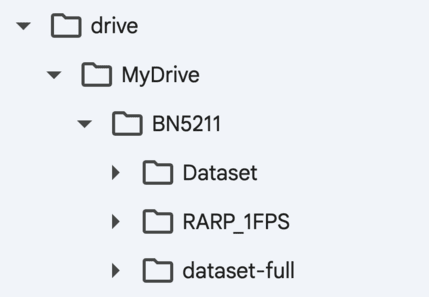

### Importing libraries

Please import the basic libraries and set the running device.

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torch.utils.data.dataset as Dataset
import torch.nn as nn

from PIL import Image
from torchvision import models

In [ ]:
if torch.cuda.is_available():
  device = 'cuda:0'  # choose your device here
else:
  device = 'cpu'
print('Using device:', device)

### Prepare dataset

Use the provided surgical-instrument dataset and the following data-loading code.

In [ ]:
path_train = os.path.join(dataset_root, 'train')
path_val = os.path.join(dataset_root, 'val')
path_test = os.path.join(dataset_root, 'test')

img_list_train = []
img_list_val = []
img_list_test = []

size_train = 0
size_val = 0
size_test = 0

# read all images' path
for root,dirs,files in os.walk(path_train):
  for file in files:
    img_list_train.append(os.path.join(root, file))
size_train = len(img_list_train)

for root,dirs,files in os.walk(path_val):
  for file in files:
    img_list_val.append(os.path.join(root, file))
size_val = len(img_list_val)

for root,dirs,files in os.walk(path_test):
  for file in files:
    img_list_test.append(os.path.join(root, file))
size_test = len(img_list_test)

In [ ]:
# define the data class
class ImageDataset(Dataset.Dataset):
  def __init__(self, img_list, is_train=True):
    self.img_list = img_list
    self.is_train = is_train
    self.augmentation_transforms = torchvision.transforms.Compose([
      torchvision.transforms.RandomHorizontalFlip(),
      torchvision.transforms.RandomVerticalFlip(),
      torchvision.transforms.RandomRotation(90)
    ])
    self.resize = torchvision.transforms.Resize((175, 300))
    self.image_transforms = torchvision.transforms.Compose([
      torchvision.transforms.ToTensor(),
      torchvision.transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
      )
    ])
    self.label_dict = {
      'Bi': 0,
      'Cl': 1,
      'Gr': 2,
      'Ho': 3,
      'Ir': 4,
      'Sc': 5,
      'Sp': 6
    }

  def __len__(self):
    return len(self.img_list)

  def __getitem__(self, index):
    # image name looks like 'v01_007125_Gr.jpg'
    lab_value = self.img_list[index].split('_')[-1].split('.')[0]
    label = self.label_dict[lab_value]
    img_path = self.img_list[index]
    image = Image.open(img_path).convert('RGB')
    image = self.resize(image)

    # data augmentation for training
    if self.is_train:
      image = self.augmentation_transforms(image)

    image_tensor = self.image_transforms(image)
    image = np.array(image)
    label = torch.tensor(label, dtype=torch.long)

    return image, image_tensor, label


In [ ]:
# build dataset
dataset_train = ImageDataset(img_list_train, True)
dataset_val = ImageDataset(img_list_val, False)
dataset_test = ImageDataset(img_list_test, False)

To test and visualize the dataset loading.

In [ ]:
# The visual result can be changed by changing the value of __getitem__(1)
image1, image_norm1, label1 = dataset_train.__getitem__(1)  # due to different random seed, the result may vary
plt.imshow(image1, interpolation='bilinear')
plt.show()

## Task 1: Building and analysing CNNs for surgical instrument classification [40%]

In this task, you will build a convolutional neural network to classify seven surgical instruments: Bipolar, Clipper, Grasper, Hook, Irrigator, Scissors, and Specimen Bag. You will first develop a baseline model, then explore how several design and training choices affect its performance.

Task 1 has two main parts: **Code Implementation [20%]** (Q1.1-1.3) and **Analysis Report [20%]** (Q1.4). You can also create your own visualizations in the indicated notebook cells so that you can decide how best to communicate your results.


### **[5%] Q1.1: Implement the baseline CNN**

A convolutional neural network (CNN) is one of the most widely used architectures for computer-vision tasks such as classification, segmentation and regression. If you are new to CNNs, this [gentle guide](https://towardsdatascience.com/a-comprehensive-guide-to-convolutional-neural-networks-the-eli5-way-3bd2b1164a53) is a good starting point.

Complete the `ConvNet` class below by following the TODOs. Use the layer names specified in the code (`conv1`–`conv5`, `bn1`–`bn5`, `relu1`–`relu5`, `max1`–`max5`, and `fc1`–`fc3`), because Task 3 reuses the convolutional weights by name. Refer to the [torch.nn documentation](https://pytorch.org/docs/stable/nn.html) for the individual building blocks.

In [ ]:
class ConvNet(torch.nn.Module):
  def __init__(self):
    super().__init__()

    ##############################################################################
    # TODO: Implement the CNN architecture described below.
    # Requirements:
    # - Use convolution, batch normalization, activation (ReLU), pooling,
    #   fully connected layers, and at least one regularization method (e.g., Dropout).
    # - Input:  (B, 3, 175, 300)
    # - Output: Class logits of shape (B, 7)
    ##############################################################################

    # Block 1: 3 x 175 x 300 --> 32 x 87 x 150
    # Define self.conv1, self.bn1, self.relu1, and self.max1





    # Block 2: 32 x 87 x 150 --> 64 x 43 x 75
    # Define self.conv2, self.bn2, self.relu2, and self.max2






    # Block 3: 64 x 43 x 75 --> 128 x 21 x 37
    # Define self.conv3, self.bn3, self.relu3, and self.max3






    # Block 4: 128 x 21 x 37 --> 256 x 10 x 18
    # Define self.conv4, self.bn4, self.relu4, and self.max4






    # Block 5: 256 x 10 x 18 --> 256 x 5 x 9
    # Define self.conv5, self.bn5, self.relu5, and self.max5






    # Fully connected layers: 256 x 5 x 9 --> 2048 --> 1024 --> 7
    # Define self.fc1, self.fc2, and self.fc3







    # Dropout layer(s)


    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################

  def forward(self, x):
    ##############################################################################
    # TODO: Implement the forward pass.
    # - Pass the input through the convolutional blocks.
    # - Flatten the feature map.
    # - Apply fully connected layers with dropout.
    # - Return class logits.
    ##############################################################################

    # Block 1:         3 x 175 x 300 --> 32 x 87 x 150


    # Block 2:         32 x 87 x 150 --> 64 x 43 x 75



    # Block 3:         64 x 43 x 75 --> 128 x 21 x 37


    # Block 4:         128 x 21 x 37 --> 256 x 10 x 18


    # Block 5:         256 x 10 x 18 --> 256 x 5 x 9


    # Linear layers:   256 x 5 x 9 --> 11520 --> 2048 --> 1024 --> 7
    # Apply fc layers with dropout


    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################
    return x


model = ConvNet().to(device)
summary(model, input_size=(1, 3, 175, 300))

### **[5%] Q1.2: Implement the training and evaluation pipeline**

Next, complete the training and evaluation functions for your baseline model. Please record the training and validation results needed for the later analysis; the test set should remain unused in this section.

In [ ]:
# Baseline training configuration
batch_size = 8
criterion = torch.nn.CrossEntropyLoss()

dataloader_train = torch.utils.data.DataLoader(
  dataset_train, batch_size=batch_size, shuffle=True
)
dataloader_val = torch.utils.data.DataLoader(
  dataset_val, batch_size=batch_size, shuffle=False
)

dataloader_test = torch.utils.data.DataLoader(
  dataset_test, batch_size=batch_size, shuffle=False
)

To support your later analysis, please record training loss, training accuracy, validation loss, and validation accuracy for every epoch. Save the checkpoint with the highest validation accuracy and record the complete training history appropriately.

Your evaluation function should return the loss, accuracy, ground-truth labels, predicted labels, and class probabilities. You will use these outputs later to examine class-level performance and individual predictions.

In [ ]:
def train_net(model, dataloader_train, dataloader_val, optimizer,
              criterion, save_path, total_epochs=200):
  ##############################################################################
  # TODO: Implement training and validation.
  # Requirements:
  # - For each training batch: move data to device, zero gradients, run
  #   forward pass, compute loss, backpropagate, and update parameters.
  # - Compute sample-weighted training loss and accuracy for each epoch.
  # - Evaluate on the validation set at the end of each epoch.
  # - Save the checkpoint with the highest validation accuracy.
  # - Return a history dictionary with keys:
  #   'train_loss', 'train_accuracy', 'val_loss', and 'val_accuracy'.
  # - Do not access the test set and do not generate plots here.
  ##############################################################################














  ##############################################################################
  #                         END OF YOUR CODE
  ##############################################################################


In [ ]:
@torch.inference_mode()
def eval_on_dataset(model, dataloader):
  ##############################################################################
  # TODO: Implement evaluation.
  # Requirements:
  # - Use model.eval() and do not compute gradients.
  # - Compute sample-weighted average loss and accuracy.
  # - Collect all ground-truth labels, predicted labels, and probabilities.
  # - Return a dictionary with keys:
  #   'loss', 'accuracy', 'labels', 'predictions', and 'probabilities'.
  ##############################################################################















  ##############################################################################
  #                         END OF YOUR CODE
  ##############################################################################


Train the baseline model using SGD and batch size 8, then save its training history and best-validation checkpoint for Q1.3. As a simple debugging check, validation accuracy would normally exceed 55%; this is only a guide and not a grading threshold.

In [ ]:
# C0: baseline CNN, random initialization, SGD, batch size 8
epochs = 200
learning_rate = 0.001

model_c0 = ConvNet().to(device)
optimizer_c0 = optim.SGD(model_c0.parameters(), lr=learning_rate)

os.makedirs(weights_root, exist_ok=True)
save_path_c0 = os.path.join(weights_root, 'task1_c0_baseline_sgd_bs8.pth')

##############################################################################
# TODO: Train C0 and store its returned history for later visualization.
##############################################################################











##############################################################################
#                         END OF YOUR CODE
##############################################################################


#### Explore the baseline training process

Use the cell below to create your own visualizations of the baseline training process. At minimum, your report should include clearly labelled training and validation loss and accuracy curves, but you are free to choose the layout and presentation that communicate the results most effectively.


In [ ]:
##############################################################################
# TODO: Design and implement visualizations of the C0 training and
# validation history. You may add additional cells if needed.
##############################################################################









##############################################################################
#                         END OF YOUR CODE
##############################################################################


### **[10%] Q1.3: Implement and run the controlled comparisons**

You will now explore how four factors affect model performance:

1. **Architecture:** baseline CNN versus custom ResNet18.
2. **Optimizer:** SGD versus Adam.
3. **Batch size:** 8 versus 16.
4. **Initialization:** randomly initialized versus ImageNet-pretrained torchvision ResNet18.

Please use the configurations below so that only one intended factor changes within each comparison:

| ID | Architecture | Initialization | Optimizer | Batch size | Comparison |
|---|---|---|---|---:|---|
| C0 | Baseline CNN | Random | SGD | 8 | Baseline |
| C1 | Custom ResNet18 | Random | SGD | 8 | C0 vs. C1: architecture |
| C2 | Custom ResNet18 | Random | Adam | 8 | C1 vs. C2: optimizer |
| C3 | Custom ResNet18 | Random | Adam | 16 | C2 vs. C3: batch size |
| C4 | Torchvision ResNet18 | Random | Adam | 16 | Initialization reference |
| C5 | Torchvision ResNet18 | ImageNet | Adam | 16 | C4 vs. C5: initialization |

To keep the comparisons meaningful, use the same learning rate, epoch numbers, data split, preprocessing, and checkpoint-selection rule within each comparison. Save the history and checkpoint for each configuration separately, use validation results for comparison, and leave the test set untouched until the final model has been selected.


In [ ]:
# Define a custom ResNet18 without using torchvision.models.

class ResNet18Custom(torch.nn.Module):
    ##############################################################################
    # TODO: Implement a ResNet-18 from scratch (without torchvision.models).
    # - Refer to He et al., CVPR 2016 (arXiv:1512.03385).
    # - You may consult the official PyTorch implementation:
    #   https://github.com/pytorch/vision/blob/main/torchvision/models/resnet.py
    # - Do not copy-paste; instead, understand the architecture and write
    #   your own implementation.
    ##############################################################################

















class ResidualBlock(nn.Module):
    ##############################################################################
    # TODO: Implement a basic residual block, including the shortcut needed
    # when the spatial resolution or number of channels changes.
    ##############################################################################

















##############################################################################
# TODO: Print the custom ResNet18 summary and verify its output shape.
##############################################################################







##############################################################################
#                 END OF YOUR CODE
##############################################################################

In [ ]:
# C1: custom ResNet18, random initialization, SGD, batch size 8
##############################################################################
# TODO: Train C1 using the same SGD settings, batch size, epoch budget,
# and validation protocol as C0. Save its history and best checkpoint.
##############################################################################







##############################################################################
#                         END OF YOUR CODE
##############################################################################


In [ ]:
# C2: custom ResNet18, random initialization, Adam, batch size 8
##############################################################################
# TODO: Train C2. Change only the optimizer relative to C1 and save its
# history and best-validation checkpoint separately.
##############################################################################







##############################################################################
#                         END OF YOUR CODE
##############################################################################


In [ ]:
# C3: custom ResNet18, random initialization, Adam, batch size 16
##############################################################################
# TODO: Rebuild the training dataloader with batch size 16 and train C3.
# Change only the batch size relative to C2. Save its history and best
# validation checkpoint separately.
##############################################################################








##############################################################################
#                         END OF YOUR CODE
##############################################################################


For the final comparison, you will investigate how weight initialization affects model performance. Train two torchvision ResNet18 models using the same architecture and supervised training protocol: one with randomly initialized weights and one with ImageNet-pretrained weights.

Using a model pretrained on one dataset and adapting it to a new task is known as transfer learning technique. Here, you will replace the pretrained ResNet18 classification layer with a seven-class classifier and fine-tune the model for surgical instrument classification. The pre-trained model can be obtained from the PyTorch library. Furthermore, this technique can also help you adapt the newest-trend foundation into downstream tasks, which can save you a lot of time and computational resources.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

# C4: torchvision ResNet18, random initialization, Adam, batch size 16
##############################################################################
# TODO: Train a ResNet18 from torchvision without pretrained weights.
# - Initialize ResNet18 with random weights (weights=None).
# - Replace its final classifier with a 7-class linear layer.
# - Train it using the same protocol that will be used for C5.
# - Save its history and best-validation checkpoint separately.
###############################################################################










##############################################################################
#                         END OF YOUR CODE
##############################################################################


In [ ]:
# C5: torchvision ResNet18, ImageNet initialization, Adam, batch size 16
##############################################################################
# TODO:
# - Initialize ResNet18 with pretrained weights on ImageNet (weights=ResNet18_Weights.DEFAULT).
# - Replace its final classifier with a 7-class linear layer.
# - Use exactly the same supervised training protocol as C4.
# - Save its history and best-validation checkpoint separately.
##############################################################################






##############################################################################
#                         END OF YOUR CODE
##############################################################################


#### Select and evaluate your final model

Review the validation results from C0–C5 and select the final configuration before accessing the test set. Once your choice has been recorded, load its best-validation checkpoint and evaluate it on the test set.


In [ ]:
##############################################################################
# TODO: Select the final configuration using validation evidence only.
# Then load its best checkpoint and evaluate dataloader_test exactly once.
# Retain the returned labels, predictions, etc. for Q1.4.
##############################################################################

selected_configuration = None  # Replace with the configuration of C0, C1, etc. according to your choice



##############################################################################
#                         END OF YOUR CODE
##############################################################################


#### Prepare your Task 1 results

Use the cell below to create the figures and numerical summaries needed for your Q1.4 Analysis Report. You may organize them in any clear and appropriate way, and you are welcome to add more cells if needed.


In [ ]:
##############################################################################
# TODO: Create the Task 1 figures and numerical summaries required by the
# Analysis Report, including but not limited to:
# - training/validation loss and accuracy across configurations;
# - a numerical table for the four controlled comparisons;
# - class-level evaluation of the selected final model;
# - representative correct and incorrect predictions.
# You may add additional cells as needed.
##############################################################################










##############################################################################
#                         END OF YOUR CODE
##############################################################################


### **[20%] Task 1 - Analysis Report**

Please present the following analysis in the separate PDF report. The code used to generate every reported figure and numerical result should remain in your submitted notebook, no need to show the code in the report.

- **A1.1 - Model-design explanation [2%]:** Briefly explain the implemented CNN architecture and the roles of its main components.

- **A1.2 - Training process and learning dynamics [6%]:** Use your visualizations to explain how training and validation performance change across epochs. Discuss convergence speed, stability, and any evidence of underfitting or overfitting.

- **A1.3 - Comparison analysis [6%]:** Compare the effects of architecture, optimizer, batch size, and ImageNet pretraining using validation results. Report the size of each performance change and discuss plausible reasons for what you observe.

- **A1.4 - Model selection and failure analysis [6%]:** Explain why you selected the final model, then report its test-set evaluation. Examine its class-level performance and representative correct and incorrect predictions, and discuss any recurring failure patterns you notice.

## Task 2: Surgical Action Recognition [25%]

In this task, you will move from instrument classification to action recognition in surgical images. The goal is to recognize fine-grained surgical actions (e.g., “picking up the needle”, “knot tying”) from individual frames sampled from a long procedure. Unlike instrument classification, action recognition is more challenging because a single frame may be visually ambiguous, and distinguishing between actions requires robust spatial feature extraction. This setting introduces challenges such as visual occlusions, class imbalance, and the high similarity between different actions.

We will start from a simple, strong baseline and train it end-to-end: **ResNet → Classifier**. As illustrated in the figure, the pipeline (i) takes a single frame as input, (ii) extracts features with a ResNet18 backbone (with pretrained ImageNet weights), and (iii) outputs an action label for frame-level prediction.

Task 2 consists of **Code Implementation [13%]** and **Analysis Report [12%]**. You will create your own visualizations in the indicated notebook cells.


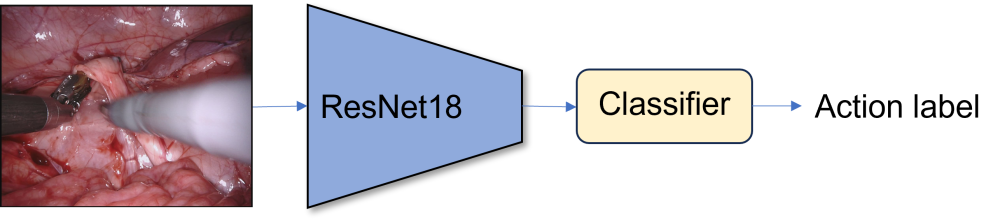

### **[5%] Q2.1: Implement the action-recognition dataset**

The dataset is organized by surgical sequence. Each sequence has an image folder and a corresponding annotation file containing comma-separated rows in the format:

```text
start_frame,end_frame,class_id
```

Both range endpoints are inclusive. For example, `120,184,3` assigns class 3 to frames 120 through 184.

Complete `RARPReader` and `RARPDataset` so that they:

- discover and sort valid image files;
- load the annotated frame ranges;
- obtain the frame ID from the image filename and assign the correct label;
- resize images to `(256, 512)` and normalize them using ImageNet mean and standard deviation;
- apply mild spatial and/or photometric augmentation only to the training split;
- concatenate all sequence readers within a split.

Each sample should return `(image_tensor, label, image_path)`. The image path will be useful later when you examine prediction errors.

In [ ]:
# Imports required for Task 2
# Uncomment the next line if torchinfo is not already installed.
# !pip install -q torchinfo

import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torch.utils.data.dataset as Dataset
import torchvision

from PIL import Image
from sklearn.metrics import f1_score
from torch.utils.data import ConcatDataset
from torchinfo import summary
from torchvision.models import resnet18, ResNet18_Weights

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)


In [ ]:
class RARPReader(data.Dataset):
  """Read individual frames and action labels from one sequence."""

  def __init__(self, seq_image_dir, seq_action_path,
               resize_hw=(256, 512), is_train=True):
    self.seq_image_dir = seq_image_dir
    self.seq_action_path = seq_action_path
    self.is_train = is_train
    self.img_list = []
    for root, dirs,files in os.walk(seq_image_dir):
        for file in files:
            self.img_list.append(os.path.join(root, file))
    self.img_list = sorted(self.img_list)
    self.label_ranges = self.load_ranges(seq_action_path)

    ##############################################################################
    # TODO: Define the resize, training augmentation, and normalization.
    # Requirements:
    # - Resize every image to resize_hw.
    # - Convert the PIL image to a tensor.
    # - Normalize using ImageNet mean/std
    # - If is_train=True, you should at least add mild spatial augmentations
    #   (e.g., ColorJitter)
    ###############################################################################








    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################

  def load_ranges(self, txt_path):
    ##############################################################################
    # TODO: Read all non-empty annotation rows.
    # Each row has: start_frame,end_frame,class_id
    # Convert the values to integers and return a list of tuples:
    # [(start_frame, end_frame, class_id), ...]
    ##############################################################################



    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################
    return ranges


  def get_label(self, frame_id, ranges):
    ##############################################################################
    # TODO: Return the class ID whose inclusive range contains frame_id.
    ##############################################################################






    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################

  def __len__(self):
    return len(self.img_list)

  def __getitem__(self, sample_idx):
    ##############################################################################
    # TODO: Load and transform one frame.
    # - Obtain frame_id from the integer filename stem; for example,
    #   00001.jpg corresponds to frame_id=1.
    # - Open the sampled image, convert to RGB, resize to (256, 512) and apply transforms
    # - If it is training, apply augmentation
    # - Return (image_tensor, label, image_path).
    ###############################################################################










    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################
    return image_tensor, label, image_path


class RARPDataset(Dataset.Dataset):
  # NOTE:
  # Action classes:
  # 0 -> Other
  # 1 -> Picking up the needle
  # 2 -> Positioning the needle tip
  # 3 -> Pushing the needle through the tissue
  # 4 -> Pulling the needle out of the tissue
  # 5 -> Tying a knot
  # 6 -> Cutting the suture
  # 7 -> Returning/dropping the needle

  def __init__(self, dataset_root, resize_hw=(256, 512), is_train=True):
    self.dataset_root = dataset_root
    self.is_train = is_train
    self.sub_readers = []

    image_root = os.path.join(dataset_root, 'images')
    action_root = os.path.join(dataset_root, 'actions')

    # ##############################################################################
    # TODO: Use RARPReader to load each sequence
    # - Instantiate a RARPReader with the given image directory and action file
    # - Append the RARPReader object to self.sub_readers
    # ##############################################################################





    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################

    # Concat all the sub-readers
    self.dataset = ConcatDataset(self.sub_readers)

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, index):
    return self.dataset[index]


### **[4%] Q2.2: Implement the frame-level ResNet18 classifier**

Build a frame-level action classifier using an ImageNet-pretrained ResNet18. Keep the ResNet18 feature extractor and global average pooling, then replace the original ImageNet classifier with an eight-class linear layer.

This task uses one frame per prediction; there is no temporal dimension or temporal averaging in the model.


In [ ]:
# build the model with pretrained ResNet18
class RARPResnet(nn.Module):
  def __init__(self, num_classes=8):
    super(RARPResnet, self).__init__()
    self.num_classes = num_classes
    ##############################################################################
    # TODO: Define the frame-level classifier.
    # Requirements:
    # - Backbone: build a ResNet18 feature extractor from torchvision with
    #   pretrained weights. Remove the final fully connected layer (keep avgpool).
    # - Classifier: a Linear head mapping d_model -> num_classes.
    ##############################################################################





    # ##############################################################################
    #              END OF YOUR CODE
    # ##############################################################################

  def forward(self, x):
    ##############################################################################
    # TODO: Implement the frame-level forward pass.
    # - Input: x with shape (B, 3, H, W).
    # - Extract one feature vector for each frame.
    # - Apply the classifier and return logits with shape (B, num_classes).
    ##############################################################################



    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################
    return logits

### **[4%] Q2.3: Implement training and evaluation**

Complete the evaluation and training functions below. Use validation performance to select the best checkpoint. After training is complete, load that checkpoint and evaluate on the test set.


In [ ]:
@torch.inference_mode()
def rarp_evaluate(model, loader, criterion, device):
  ##############################################################################
  # TODO: Evaluate the action-recognition model.
  # Requirements:
  # - Use model.eval() and do not compute gradients.
  # - Compute average loss and accuracy in [0, 1].
  # - Compute suitable metrics for reporting model performance of your choices (for later analysis)
  # - Collect ground-truth labels, predictions, probabilities, and paths.
  # - Return results in a suitable format that can be used for analysis and reporting.
  ##############################################################################






  ##############################################################################
  #                         END OF YOUR CODE
  ##############################################################################

In [ ]:
def rarp_training(model, train_loader, val_loader, optimizer, scheduler,
                  criterion, num_epochs, weights_root, device):
  ##############################################################################
  # TODO: Train and validate the action-recognition model.
  # Requirements:
  # - Complete the standard training steps for every batch.
  # - Evaluate on the validation set at periodically.
  # - Record training loss and suitable metrics for validation.
  # - Save two models:
  # (1) rarp_model_best.pth for the best validation performance;
  # (2) rarp_model.pth for the final epoch.
  # - Step the scheduler once per epoch.
  # - Return a history dictionary containing all recorded metrics.
  # - Do not access the test set and do not generate plots here.
  ##############################################################################





















  ##############################################################################
  #                         END OF YOUR CODE
  ##############################################################################

In [ ]:
# Starting hyperparameters. You may adjust them using validation results
num_epochs = 20
batch_size = 16
learning_rate = 0.0005
step_size = 8
num_classes = 8

In [ ]:
# Prepare Task 2 datasets and dataloaders.
weights_root_task2 = os.path.join(drive_root, 'weights')
dataset_root_task2 = os.path.join(drive_root, 'RARP_1FPS')

path_train_task2 = os.path.join(dataset_root_task2, 'train')
path_val_task2 = os.path.join(dataset_root_task2, 'val')
path_test_task2 = os.path.join(dataset_root_task2, 'test')

dataset_train_task2 = RARPDataset(
  path_train_task2, resize_hw=(256, 512), is_train=True
)
dataset_val_task2 = RARPDataset(
  path_val_task2, resize_hw=(256, 512), is_train=False
)
dataset_test_task2 = RARPDataset(
  path_test_task2, resize_hw=(256, 512), is_train=False
)

train_loader_task2 = torch.utils.data.DataLoader(
  dataset_train_task2, batch_size=batch_size, shuffle=True, num_workers=2
)
val_loader_task2 = torch.utils.data.DataLoader(
  dataset_val_task2, batch_size=batch_size, shuffle=False, num_workers=2
)
test_loader_task2 = torch.utils.data.DataLoader(
  dataset_test_task2, batch_size=batch_size, shuffle=False, num_workers=2
)


In [ ]:
# Instantiate the model and move it to the appropriate device
model_task2 = RARPResnet(num_classes=num_classes).to(device)

# Print the model architecture
summary(
  model_task2,
  input_size=(1, 3, 256, 512),
  col_names=('input_size', 'output_size', 'num_params'),
  depth=3,
)

# Use Adam optimizer
optimizer_task2 = optim.Adam(model_task2.parameters(), lr=learning_rate)

# Learning rate scheduler
scheduler_task2 = optim.lr_scheduler.StepLR(
  optimizer_task2, step_size=step_size, gamma=0.5
)

criterion_task2 = nn.CrossEntropyLoss().to(device)

In [ ]:
##############################################################################
# TODO: Train the Task 2 model by calling rarp_training with the required
# arguments. Store the returned history for the Analysis Report.
##############################################################################



##############################################################################
#                         END OF YOUR CODE
##############################################################################


In [ ]:
##############################################################################
# TODO: Load rarp_model_best.pth and evaluate it on test_loader_task2
# Store the returned labels, predictions, probabilities, and
# paths for the class-level and failure analyses in Q2.4.
############################################################################



##############################################################################
#                         END OF YOUR CODE
##############################################################################


#### Prepare your Task 2 results

Use the cell below to create the figures and numerical summaries needed for Q2.4. You may choose any clear and appropriate visualization style and add more cells if needed.


In [ ]:
##############################################################################
# TODO: Create the Task 2 figures and numerical summaries required by Analysis Report
# You may add additional cells as needed.
##############################################################################



##############################################################################
#                         END OF YOUR CODE
##############################################################################


### **[12%] Task 2 - Analysis Report**

Please present the following analysis in the separate PDF report. Keep the code used to generate every figure and numerical result in your submitted notebook; the report only needs to show the resulting figures, values, and discussion.

- **A2.1 - Dataset and class-distribution analysis [3%]:** Report the number of frames in each action class and discuss how the distribution may affect model performance.

- **A2.2 - Training process and learning dynamics [3%]:** Use your own visualizations to discuss convergence, training stability, and any evidence of underfitting or overfitting.

- **A2.3 - Model performance analysis [3%]:** Report and interpret test accuracy, micro-F1, macro-F1, weighted-F1, and class-level performance. Discuss why these metrics may differ, identify the best- and worst-performing classes, and explain which metric gives the most informative view of performance for this dataset.

- **A2.4 - Failure and task-limitation analysis [3%]:** Visualize representative incorrect predictions and discuss possible causes.

## Task 3: Constrastive learning **[35%]**

In Task 1, we have trained the deep learning model by optimizing the nework with the guidance of label. However, the labeling work is timeconsuming and difficult to achieve accurate label in various tasks. The reliance on large scale data of deep learning models makes us need to think: How to use the unlabeled data to benefit optimization?

### The target of constrastive learning

To use unlabeled data to benefit model optimization, contrastive learning was born. It can realize the model optimization by large unlabeled data and few labeled data. The principle of contrastive learning is: Learn the same features among instances of the same class and distinguish differences between instances of the same class. The learning process does not require the label of each instance. It can provide a pre-trained model without labels for fine-tunning.


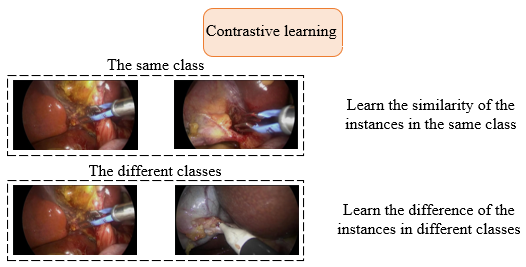

As shown in the following figure, the instances of different classes.

1. **For the positive pairs**: Because of the smilar regions (red box), the different instances of Bipolar are grouped into the same class. The backgroud regions are not important for the classification task. Hence, the distance between the two instances can be measured by the similarity calculation on the red box.
2. **For the negative pairs**: Because of the difference between Hook instance and Bipolar instance (red box), the two instances should be classified into different classes.

Hence, if a network could narrow the distance of instances in the same class and enlarge the distance of instance in the different class, this network can realize the classification without labels.

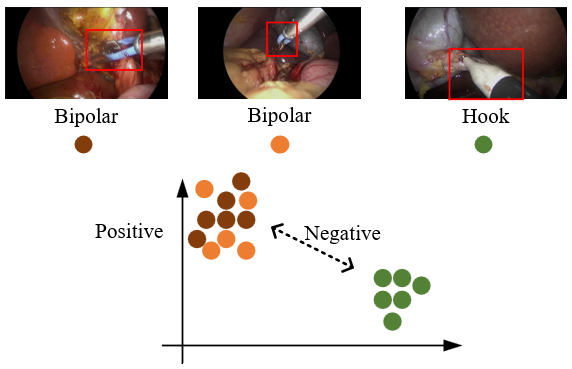

To make this ability available, contrastive learning constructs the positive and negative pairs to guide the network distingush each instance. Though comparing the similarity and difference, the network could understand the class of each instance.

There are lots of strategies in contrastive learning to realize this. Here, we conduct the strategy: guiding the network capture the similarity of instances in the same class by contrastive learning.

### Set a contrastive learning strategy

Here, we set a contrastive learning following the strategy in the figure. It consists of 3 steps:


1.   **Set contrastive pairs.** Different from the above Task 1-2, we need to construct the positive and negative pairs for comparison of similarity. Due to the lack of labels, the positive pairs cannot be find directly. Hence, we takes different data augmentation ways on the same image to generate two images as a pair (like Bipolar and Bipolar'). Because the generated images are from the same image, they must be the same class. The negative pair can be the randomly generated features.
2.   **Define the convolutional layers.** Since the target of optimization is the network for q (left network), the network for k could not have the gradient in training process. With the generated positive and negative pairs, the similarity can be calculated. For the positive pair, the similarity is enlarged. For the negative pair, the similarity is narrowed.
3.   **Training contrastive learning network.** With the defined network and dataset in step 1-2, we can conduct the model optimization without the labels. Through the training, the network could distinguish the similar instances in the same class.   
4.   **Fine-tunning on the trained network.** With the pre-trained network by contrastive learning, we can fine-tune it to realize classification by few labels.

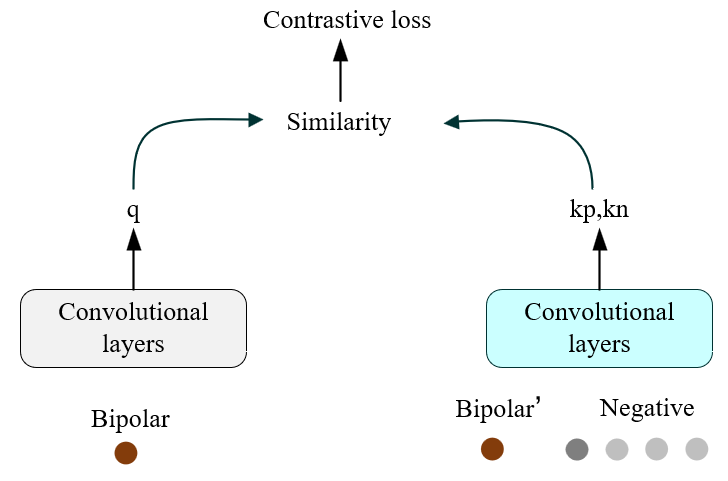

Task 3 also consists of **Code Implementation [20%]** and **Analysis Report [15%]**. Keep all implementation and visualization code in the notebook. Place the resulting figures and your written discussion in the separate Analysis Report.

### **[5%] Q3.1: Construct contrastive pairs**

Different from the dataloader in Task 1, the contrastive learning requires establishing the positive image pairs (by applying different augmentations to an image).

Implement `PairDataset` so that each item returns two independently augmented views of the same RGB image. Choose augmentations that create meaningful variation while keeping the surgical instrument recognizable, then apply ImageNet normalization to both views. Class labels are not returned.

In [ ]:
class PairDataset(Dataset.Dataset):
  def __init__(self, img_list, is_train=True):
    self.img_list = img_list
    self.is_train = is_train

    ##############################################################################
    # TODO: Define the transform used to create each view.
    # Requirements:
    # - Resize to (175, 300).
    # - Include suitable random train-time augmentations
    #   Can use simple augmentations such as random flip and random rotation
    # - Convert to a tensor and apply ImageNet normalization
    ##############################################################################



    ##############################################################################
    #                         END OF YOUR CODE
    ##############################################################################

  def __len__(self):
    return len(self.img_list)

  def __getitem__(self, index):
    img_name = self.img_list[index]
    image = Image.open(img_name)
    image = self.resize(image)

    ##############################################################################
    # TODO: Generate two different augmented views of the same image.
    # - Apply the augmentation transforms independently on the resized image
    # - Each call should produce a different random view (positive pair)
    ##############################################################################

    # Perform augmentation to get image1

    # Perform augmentation to get image2


    ##############################################################################
    #             END OF YOUR CODE
    ##############################################################################

    image1 = self.image_transforms(image1)
    image2 = self.image_transforms(image2)

    return image1, image2

Build the pretraining dataloader below. `drop_last=True` is required because the simplified queue implementation in Q3.2 uses a fixed batch size that must divide the queue size.

In [ ]:
# Read all images' path
img_list_train_full = []
for root, dirs, files in os.walk(full_dataset_dir):
  for file in files:
    img_list_train_full.append(os.path.join(full_dataset_dir, file))
size_train_full = len(img_list_train_full)

contrastive_batch_size = 8
train_full_data = PairDataset(img_list_train_full, True)

# Train_dataloader should drop_last to prevent error in the queue of contrastive learning
train_full_loader = torch.utils.data.DataLoader(dataset=train_full_data,
                                                batch_size=contrastive_batch_size,
                                                shuffle=True,
                                                drop_last=True)

Before training, inspect several positive pairs to check that the two views are different but still preserve the instrument information. Write your own visualization code; reverse ImageNet normalization before displaying images.

In [ ]:
################################################################################
# TODO: (for later analysis)
# Write your own code to visualize at least three positive pairs.
# You can add cells if needed
################################################################################



################################################################################
#                         END OF YOUR CODE
################################################################################


### **[8%] Q3.2: Implement the encoder and MoCo model**

Based on the defined ConvNet in Task 1, we construct the contrastive learning model. Compared with the ConvNet in Task 1, we just reduce two linear layers in the end.

First implement `ConvNetNew`, which follows the five convolutional blocks used by the Task 1 `ConvNet` but replaces its classification layers with adaptive average pooling and a 128-dimensional projection. Keep the layer names `conv1`–`conv5`, `bn1`–`bn5`, `relu1`–`relu5`, and `max1`–`max5`, so that the pretrained convolutional weights can be loaded into the Task 1 classifier in Q3.4.

In [ ]:
class ConvNetNew(torch.nn.Module):
  def __init__(self):
    super().__init__()
    ##############################################################################
    # TODO: Build a CNN encoder (representation learning).
    # Requirements:
    # - Stack multiple Conv-BN-ReLU-MaxPool blocks
    # - Apply AdaptiveAvgPool2d to reduce features to 1×1
    # - Replace the final linear layers with a 256→128 projection head
    # - Output a 128-D feature embedding (no classifier here)
    # - Input: (B,3,H,W), H,W≥64; Output: (B,128); Do NOT hard-code H,W
    ##############################################################################

    # Block 1: 3 x 175 x 300 --> 32 x 87 x 150
    # Define self.conv1, self.bn1, self.relu1, and self.max1





    # Block 2: 32 x 87 x 150 --> 64 x 43 x 75
    # Define self.conv2, self.bn2, self.relu2, and self.max2



    # Block 3: 64 x 43 x 75 --> 128 x 21 x 37
    # Define self.conv3, self.bn3, self.relu3, and self.max3



    # Block 4: 128 x 21 x 37 --> 256 x 10 x 18
    # Define self.conv4, self.bn4, self.relu4, and self.max4



    # Block 5: 256 x 10 x 18 --> 256 x 5 x 9
    # Define self.conv5, self.bn5, self.relu5, and self.max5




    # Define self.aap using AdaptiveAvgPool2d
    # 256 x 5 x 9 --> 256 x 1 x 1


    # Define the contrastive projection layer as self.fc1
    # 256 --> 128


    ##############################################################################
    #            END OF YOUR CODE
    ##############################################################################

  def forward(self, x):
    ##############################################################################
    # TODO: implement the forward
    ##############################################################################

    # Block 1: 3 x 175 x 300 --> 32 x 87 x 150


    # Block 2: 32 x 87 x 150 --> 64 x 43 x 75


    # Block 3: 64 x 43 x 75 --> 128 x 21 x 37


    # Block 4: 128 x 21 x 37 --> 256 x 10 x 18


    # Block 5: 256 x 10 x 18 --> 256 x 5 x 9


    # AdaptiveAvgPool: 256 x 1 x 1


    # Linear layers: 256 x 1 x 1 --> 128


    ##############################################################################
    #            END OF YOUR CODE
    ##############################################################################
    return x


With the defined convolution layers (ConvNetNew()), the whole contrastive learning framework could be constructed. The encoder_q and encoder_k have the same convolutional layers. However, the encoder_k will not be optimized by the training (the gradient of encoder_k should be set False). To update the parameters of encoder_k, the parameters will copy encoder_q's.

In [ ]:
class ConLNet(torch.nn.Module):
  def __init__(self):
    super(ConLNet, self).__init__()
    ##############################################################################
    # TODO: Define the convolutional encoders q & k
    # Tips: refer to: https://arxiv.org/abs/1911.05722 and https://github.com/facebookresearch/moco
    # Requirements:
    # - Build encoder_q and encoder_k based on ConvNetNew
    # - Initialize encoder_k with encoder_q’s parameters
    # - Set encoder_k parameters to not require gradients
    # - Follow MoCo design (refer to paper and codebase)
    # - Use a momentum update for encoder_k in forward: k = m*k + (1-m)*q (under torch.no_grad())
    # - Maintain a feature queue (dim=128, size=K) as buffers (register_buffer) and L2-normalize q/k
    # - Set encoder_k.eval() during forward to freeze BN running stats
    ##############################################################################

    # Create encoder_q and encoder_k  Hint: define the encoder_q and encoder_k based on ConvNetNew()


    # Copy encoder_q's paremeter to encoder_k, and set requires_grad of parameter to False



    # Set temperature for infoNCE (T=0.07), momentum updating (m=0.99), feature dimension (dim=128), queue size (K=160)
    # Temperature for infoNCE

    # Momentum updating

    # Feature dimension

    # Queue size

    # Set a queue pointer (queue_ptr) to manage the queue, which helps locate the position of queue

    # Create the 128 negative instance features by torch.randn, feature size is dim, queue size is K



  def infoNCE(self, q, k):
    # Positive logits: Nx1 （Multiply the corresponding elements of the matrix and sum them row by row) on q and k

    # Negative logits: NxK  (matrix product) on q and the negative sample


    # Concat logits: Nx(1+K)

    # Apply temperature to logits


    # Set labels

    # Calculate infoNCE by CrossEntropy using nn.functional.cross_entropy


    return loss

  # Organize the queue when new keys are coming
  def _dequeue_and_enqueue(self, keys):
    # Get batch_size


    # For simplicity, assert self.K % batch_size == 0

    # Replace the keys at ptr (dequeue and enqueue) in the queue

    # Move pointer, and save it to self.queue_ptr for the next usage



  def forward(self, im1, im2):
    # Copy encoder_q's parameters to encoder_k with momentum update with torch.no_grad():
    # Encoder_k = self.m * encoder_k + (1 - self.m) * encoder_q



    # Compute features of q and k with encoder_q and encoder_k using im1 and im2, and then normalize the feature
    # Since the encoder_k is update with momentum update, remember to open torch.no_grad() when using encoder_k





    # Calculate the loss of q and k


    # Use  _dequeue_and_enqueue to store k


    return loss

    ##############################################################################
    #             END OF YOUR CODE
    ##############################################################################

### **[4%] Q3.3: Run contrastive pretraining**

From Q3.1 to Q3.2, the contrastive learning model and dataloader are defined. In this section, we will build up the forward process of contrastive learning. Without the label of each data, the loss is calculated by comparing the similarity of the features extracted by two parallel encoders. Save the trained query encoder for Q3.4.

In [ ]:
def train_contrastive_net(model, train_loader, optimizer, save_path, total_epochs=200):
  # Train contrastive learning
  epoch_losses = []
  model.train()
  for epoch in range(total_epochs):
    running_loss = 0.0
    for image1_norm, image2_norm in train_loader:
      ##############################################################################
      # TODO: Complete the forward process
      # Requirements:
      # - Move both augmented views to device
      # - Forward through the model to get contrastive loss (infoNCE)
      # - Zero gradients, backpropagate, and update parameters
      # - Accumulate running loss for logging
      ##############################################################################


      # Calculate the loss by the defined model above


      # Backward the loss and optimize the model



      ##############################################################################
      #            END OF YOUR CODE
      ##############################################################################
    avg_loss = running_loss / len(train_loader)
    epoch_losses.append(avg_loss)
    print('epoch= {} \t loss= {:.3f}'.format(epoch, avg_loss))

  # We only save encoder_q
  assert model.encoder_q is not None
  torch.save(model.encoder_q.state_dict(), save_path)
  print(f'Query encoder saved to {save_path}')

  return epoch_losses

In [ ]:
# Initialize the MoCo model
contrastive_model = ConLNet().to(device)

# Hyperparameters
contrastive_learning_rate = 1e-3
contrastive_epochs = 200
contrastive_optimizer = optim.Adam(
  contrastive_model.encoder_q.parameters(),
  lr=contrastive_learning_rate,
)

contrastive_encoder_path = os.path.join(
  weights_root, 'task3_contrastive_encoder.pth'
)

# Run contrastive learning training
contrastive_loss_history = train_contrastive_net(
  contrastive_model,
  train_full_loader,
  contrastive_optimizer,
  contrastive_encoder_path,
  total_epochs=contrastive_epochs,
)

#### Prepare the learned-representation analysis

Use the next cell to analyse the frozen pretrained encoder before supervised fine-tuning (Detailed requirements are in Q3.5). You may add additional cells if needed.

In [ ]:
################################################################################
# TODO: (for later analysis)
# Design suitable visualizations or quantitative diagnostics
# Possible approaches include similarity distributions, nearest-neighbour
# retrieval, feature-space visualization, or other appropriate methods
################################################################################





################################################################################
#                         END OF YOUR CODE
################################################################################

### **[3%] Q3.4**: Fine-tunning on the trained network.

With the pre-trained network by contrastive learning, we can fine-tune it to realize classification by few labels. We need to load the pre-trained model for fine-tunning.

In [ ]:
# Load pre-trained model
model_ft = ConvNet().to(device)

contrastive_model_path = os.path.join(weights_root, 'task3_contrastive_model.pth')

# Load the query-encoder checkpoint saved in Q3.3
pretrained_dict = torch.load(
  contrastive_encoder_path,
  map_location=device,
  weights_only=True,
)

for key in list(pretrained_dict.keys()):
  # Only leave the backbone module, popping the linear layers
  if 'fc' in key:
    pretrained_dict.pop(key)
    print('Pretrained key {} removed'.format(key))

missing_keys, unexpected_keys = model_ft.load_state_dict(pretrained_dict, strict=False)
print('Model loaded from %s' % contrastive_model_path)
print('missing key: ', missing_keys)
ft_model_is_trained = False
# Since the contrastive model has different linear layers, the missing keys are fc1, fc2, fc3

Based on the pre-trained model, we can conduct few round fine-tunning.

In [ ]:
finetune_batch_size = 8
criterion = torch.nn.CrossEntropyLoss()

# Build data loaders
dataset_train = ImageDataset(img_list_train, True)
dataset_val = ImageDataset(img_list_val, False)
dataset_test = ImageDataset(img_list_test, False)

# Build the training dataloader
dataloader_train = torch.utils.data.DataLoader(
  dataset=dataset_train,
  batch_size=finetune_batch_size,
  shuffle=True,
)

# Build the validation dataloader
dataloader_val = torch.utils.data.DataLoader(
  dataset=dataset_val,
  batch_size=finetune_batch_size,
  shuffle=False,
)

# Build the test dataloader
dataloader_test = torch.utils.data.DataLoader(
  dataset=dataset_test,
  batch_size=finetune_batch_size,
  shuffle=False,
)

In [ ]:
# Set the fine-tuning hyperparameters
total_epochs = 200
learning_rate = 1e-3

if ft_model_is_trained:
    print('Warning: the ft_model is already trained!')
else:
    ft_model_is_trained = True
finetune_model_path = os.path.join(weights_root, 'model_ft_task3.pth')
##############################################################################
# TODO: Fine-tune `model_ft`.
# - Set hyperparameters (epochs, batch_size, learning_rate)
# - Define an optimizer for trainable params of `model_ft` (e.g., Adam)
# - Train with `train_net` and save the best checkpoint
# - Reload the saved weights and evaluate on the test set
##############################################################################




# Set up optimizer


# Start training


# Start testing


# ##############################################################################
#                          END OF YOUR CODE
# ##############################################################################

In [ ]:
################################################################################
# TODO: (for later analysis)
# Write your own code to visualize the training and validation loss and
# accuracy across fine-tuning epochs
################################################################################




################################################################################
#                         END OF YOUR CODE
################################################################################

### **[15%] Task 3 - Analysis Report**

Please present the following analysis in the separate PDF report. Include the resulting figures and numerical evidence, but keep all code in the notebook.

- **A3.1 - Contrastive-pair and augmentation analysis [5%]:** Show several positive pairs produced by your dataset and discuss whether your augmentations preserve information needed to recognize the instrument. Explain both the intended benefit and any risk introduced by the transformations you selected.

- **A3.2 - Learned-representation analysis [5%]:** Use the frozen pretrained encoder to analyse its learned representations. Perform the main representation analysis using the labelled training split, and use the validation split to examine whether the observed representation structure generalizes to unseen images. Design appropriate visualizations and/or quantitative diagnostics to investigate: (1) whether different augmented views of the same image are close in feature space; and (2) whether images from the same instrument class tend to be more closely grouped than images from different classes. Possible approaches include but not limited to similarity distributions, nearest-neighbour analysis, feature-space visualization, etc. Interpret the observed structure, class patterns, and representative failure cases.

- **A3.3 - Fine-tuning and transfer analysis [5%]:** Present the training and validation loss and accuracy across fine-tuning epochs, then discuss convergence, stability, and evidence of overfitting or underfitting. Report the validation performance used for checkpoint selection and the final performance of the selected checkpoint on the test set. Explain what the results suggest about transferring the contrastively pretrained encoder to instrument classification.